# Hierarchical Bayesian Kalman Filter Model (Bandit Task)
This notebook implements a Hierarchical Bayesian Kalman Filter model on the four-armed bandit task behavioral data. We test whether generalized anxiety symptoms (measured via GAD-7 scores) predict learning parameters:
1. **Process Noise $Q$ (Drift Variance):** How fast subject-level beliefs about card rewards drift/fluctuate over time.
2. **Observation Noise $R$ (Measurement Variance):** How volatile/noisy card reward feedback is assumed to be by the subject.

The subject-level parameters are modeled as log-linear functions of GAD-7:
- $Q_{sub} = \exp(\text{int}_Q + \text{slope}_Q \cdot \text{GAD7}_{normalized})$
- $R_{sub} = \exp(\text{int}_R + \text{slope}_R \cdot \text{GAD7}_{normalized})$

We run sampling using JAX-backed NUTS (`numpyro`) and analyze the credible intervals (89% HDI) of the slopes.


In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"

import pandas as pd
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import matplotlib.pyplot as plt
import arviz as az
import warnings

warnings.filterwarnings('ignore')


In [2]:
# Load Data
file_path = '../data/allsubs_combined.csv'
df = pd.read_csv(file_path)

# Filter out trials with missing choices OR missing GAD7 scores
df = df.dropna(subset=['ChoiceKey', 'GAD7']).copy()

# Map stimulus IDs
stim_map = {'W1': 0, 'W2': 1, 'L1': 2, 'L2': 3}
df['LeftID_int'] = df['LeftID'].map(stim_map)
df['RightID_int'] = df['RightID'].map(stim_map)
df['ChosenID_int'] = df['ChosenID'].map(stim_map)

# Map ChoiceKey (Choice is 0 for Left, 1 for Right)
df['Choice'] = df['ChoiceKey'] - 1

# Scale rewards (Divide by 30.0 to map points to [0, 1] range)
df['RewardScaled'] = df['TrialPoints'] / 30.0

# Create SubIdx (0 to n_sub-1)
unique_subs = df['Sub'].unique()
sub_idx_map = {sub: i for i, sub in enumerate(unique_subs)}
df['SubIdx'] = df['Sub'].map(sub_idx_map)
n_sub = len(unique_subs)

# Mark the first trial of each subject
df['is_first'] = 0
for sub in unique_subs:
    sub_indices = df[df['Sub'] == sub].index
    if len(sub_indices) > 0:
        df.loc[sub_indices[0], 'is_first'] = 1

# Extract and normalize GAD7 scores at the subject level
# Max possible score for GAD7 is 21. Normalizing to [0, 1] keeps sampling stable.
sub_gad7_map = df.groupby('SubIdx')['GAD7'].first()
gad7_scores = np.array([sub_gad7_map[i] for i in range(n_sub)])
gad7_normalized = gad7_scores / 21.0

print(f"Total subjects included: {n_sub} (Subjects with missing GAD7 removed)")
print(f"Total trials: {len(df)}")


Total subjects included: 67 (Subjects with missing GAD7 removed)
Total trials: 6520


In [3]:
def kalman_bandit_step(left_id, right_id, chosen_id, reward, is_first, sub_idx, 
                       mu_seq, sigma2_seq, Q_vector, R_vector):
    
    # 1. Time Update (Predict / Drift Step)
    # If it's the first trial, reset states to mu=0.5, sigma2=1.0; otherwise, inject process noise (Q)
    mu_pred = pt.switch(is_first, 0.5, mu_seq[sub_idx])
    sigma2_pred = pt.switch(is_first, 1.0, sigma2_seq[sub_idx] + Q_vector[sub_idx])
    
    # Extract prediction elements for the chosen card
    mu_chosen = mu_pred[chosen_id]
    sigma2_chosen = sigma2_pred[chosen_id]
    
    # 2. Measurement Update (Correct / Learn Step)
    pe = reward - mu_chosen  # Prediction Error
    
    # Kalman Gain calculation: K = Sigma_pred / (Sigma_pred + R)
    K = sigma2_chosen / (sigma2_chosen + R_vector[sub_idx])
    
    # Update hidden state beliefs for the chosen card index
    mu_updated_chosen = mu_chosen + K * pe
    sigma2_updated_chosen = (1.0 - K) * sigma2_chosen
    
    # Reconstruct vectors (Only update chosen index, unchosen ones carry forward)
    mu_next = pt.set_subtensor(mu_pred[chosen_id], mu_updated_chosen)
    sigma2_next = pt.set_subtensor(sigma2_pred[chosen_id], sigma2_updated_chosen)
    
    # Store global state matrix update (other subjects' states are untouched)
    mu_new_matrix = pt.set_subtensor(mu_seq[sub_idx], mu_next)
    sigma2_new_matrix = pt.set_subtensor(sigma2_seq[sub_idx], sigma2_next)
    
    # Calculate action values for tracking choice likelihood
    q_left = mu_pred[left_id]
    q_right = mu_pred[right_id]
    
    return mu_new_matrix, sigma2_new_matrix, q_left, q_right


In [4]:
def build_kalman_model(df, n_sub, gad7_normalized):
    with pm.Model() as kf_model:
        # GAD7 array as constant data
        gad7_data = pm.Data("gad7_data", gad7_normalized)
        
        # Drifting (Process Noise Q) Hyperparameters
        int_Q = pm.Normal('int_Q', mu=-2, sigma=1)
        slope_Q = pm.Normal('slope_Q', mu=0, sigma=1.5)
        Q_sub = pm.Deterministic('Q_sub', pm.math.exp(int_Q + slope_Q * gad7_data))
        
        # Uncertainty / Volatility (Observation Noise R) Hyperparameters
        int_R = pm.Normal('int_R', mu=-1, sigma=1)
        slope_R = pm.Normal('slope_R', mu=0, sigma=1.5)
        R_sub = pm.Deterministic('R_sub', pm.math.exp(int_R + slope_R * gad7_data))
        
        # Inverse Temperature (Choice Stochasticity Beta)
        mu_beta_log = pm.Normal('mu_beta_log', mu=1, sigma=1)
        sigma_beta = pm.HalfNormal('sigma_beta', sigma=0.5)
        beta_raw = pm.Normal('beta_raw', mu=0, sigma=1, shape=n_sub)
        beta = pm.Deterministic('beta', pm.math.exp(mu_beta_log + beta_raw * sigma_beta))
        
        # Hidden state initial configurations
        mu_init = pt.zeros((n_sub, 4)) + 0.5
        sigma2_init = pt.ones((n_sub, 4)) * 1.0
        
        # Sequential loops over trials using PyTensor Scan
        results, _ = pytensor.scan(
            fn=kalman_bandit_step,
            sequences=[
                pt.as_tensor_variable(df['LeftID_int'].values),
                pt.as_tensor_variable(df['RightID_int'].values),
                pt.as_tensor_variable(df['ChosenID_int'].values),
                pt.as_tensor_variable(df['RewardScaled'].values),
                pt.as_tensor_variable(df['is_first'].values),
                pt.as_tensor_variable(df['SubIdx'].values)
            ],
            outputs_info=[mu_init, sigma2_init, None, None],
            non_sequences=[Q_sub, R_sub],
            strict=True
        )
        
        q_left_seq = results[2]
        q_right_seq = results[3]
        
        # Softmax probabilistic choice link function
        sub_idx_seq = pt.as_tensor_variable(df['SubIdx'].values)
        p_right_raw = pm.math.sigmoid(beta[sub_idx_seq] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        
        pm.Bernoulli('choice_obs', p=p_right, observed=df['Choice'].values)
        
    return kf_model

print("Building Hierarchical Kalman Filter model...")
kf_model = build_kalman_model(df, n_sub, gad7_normalized)


Building Hierarchical Kalman Filter model...


In [5]:
print("Sampling posterior using numpyro...")
with kf_model:
    idata_kf = pm.sample(nuts_sampler="numpyro", draws=1000, tune=1000, chains=4, progressbar=True)
print("Sampling complete!")


Sampling posterior using numpyro...


  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

Sampling complete!


In [6]:
# Extract slopes
slope_Q_samples = idata_kf.posterior['slope_Q'].values.flatten()
slope_R_samples = idata_kf.posterior['slope_R'].values.flatten()

# Calculate 89% HDI
hdi_Q = az.hdi(slope_Q_samples, hdi_prob=0.89)
hdi_R = az.hdi(slope_R_samples, hdi_prob=0.89)

# Helper to check if 0 is included in HDI
def check_significance(hdi, slope_name):
    includes_zero = hdi[0] <= 0 <= hdi[1]
    status = "INCLUDES 0 (Not strictly credible at 89%)" if includes_zero else "EXCLUDES 0 (Credible effect at 89%)"
    print(f"{slope_name} HDI 89%: [{hdi[0]:.3f}, {hdi[1]:.3f}] -> {status}")

print("==================================================")
print("KALMAN FILTER GAD-7 REGRESSION RESULTS (89% HDI)")
print("==================================================")
check_significance(hdi_Q, "Slope Q (Process Noise)")
check_significance(hdi_R, "Slope R (Observation Noise)")
print("==================================================\n")


KALMAN FILTER GAD-7 REGRESSION RESULTS (89% HDI)
Slope Q (Process Noise) HDI 89%: [-0.805, 2.229] -> INCLUDES 0 (Not strictly credible at 89%)
Slope R (Observation Noise) HDI 89%: [-0.637, 1.032] -> INCLUDES 0 (Not strictly credible at 89%)



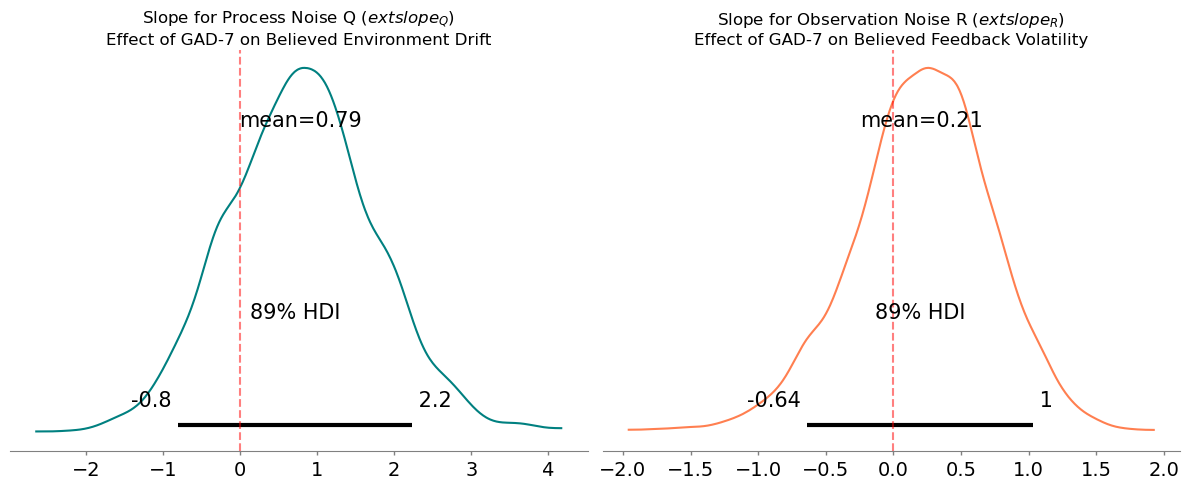

In [7]:
# Plot Posteriors of the slopes
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

az.plot_posterior(idata_kf.posterior, var_names=['slope_Q'], hdi_prob=0.89, ax=axes[0], color="teal")
axes[0].set_title("Slope for Process Noise Q ($\text{slope}_Q$)\nEffect of GAD-7 on Believed Environment Drift")
axes[0].axvline(0, color='red', linestyle='--', alpha=0.5)

az.plot_posterior(idata_kf.posterior, var_names=['slope_R'], hdi_prob=0.89, ax=axes[1], color="coral")
axes[1].set_title("Slope for Observation Noise R ($\text{slope}_R$)\nEffect of GAD-7 on Believed Feedback Volatility")
axes[1].axvline(0, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


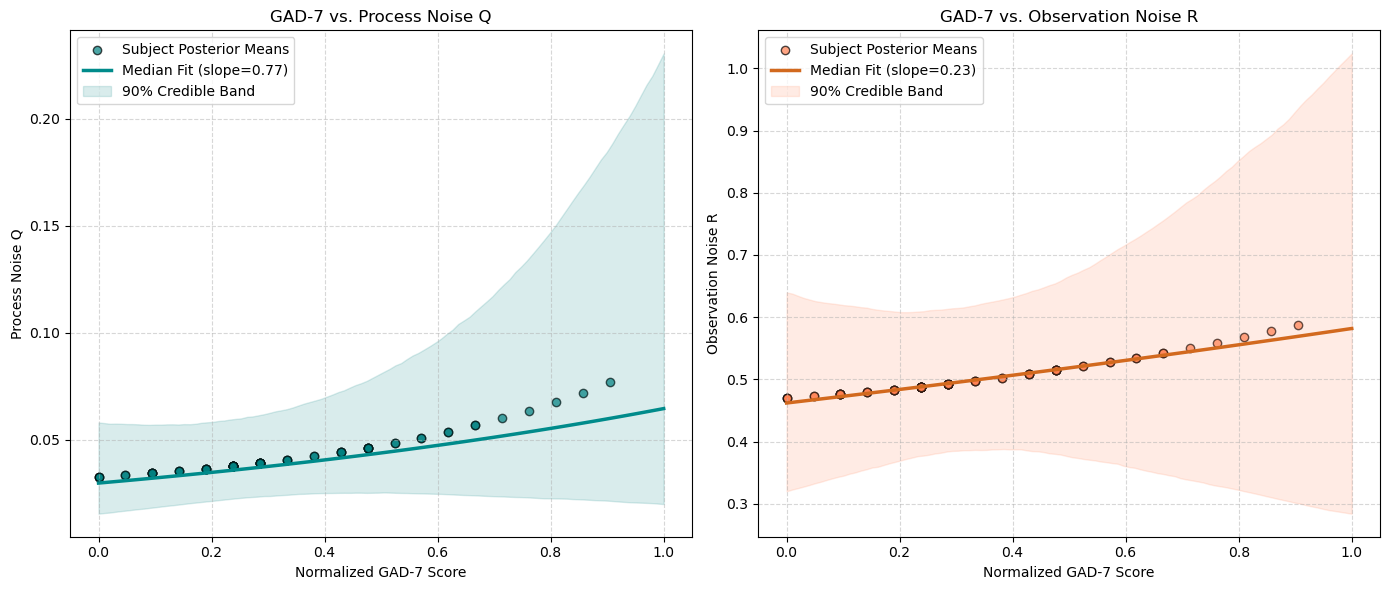

In [8]:
# Extract posterior parameters for fit lines
int_Q_samples = idata_kf.posterior['int_Q'].values.flatten()
int_R_samples = idata_kf.posterior['int_R'].values.flatten()

# Get subject-level posterior means for Q_sub and R_sub
q_sub_means = idata_kf.posterior['Q_sub'].mean(dim=['chain', 'draw']).values
r_sub_means = idata_kf.posterior['R_sub'].mean(dim=['chain', 'draw']).values

# Plot subject-level parameter values vs GAD-7
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
x_vals = np.linspace(0, 1, 100)

# Process Noise Q plot
axes[0].scatter(gad7_normalized, q_sub_means, color='teal', alpha=0.7, edgecolors='k', label='Subject Posterior Means')
# Median fit line
int_Q_med = np.median(int_Q_samples)
slope_Q_med = np.median(slope_Q_samples)
y_vals_Q = np.exp(int_Q_med + slope_Q_med * x_vals)
axes[0].plot(x_vals, y_vals_Q, color='darkcyan', linewidth=2.5, label=f'Median Fit (slope={slope_Q_med:.2f})')
# 90% credible band of regression curve
y_paths_Q = np.exp(int_Q_samples[:, None] + slope_Q_samples[:, None] * x_vals[None, :])
y_q05 = np.percentile(y_paths_Q, 5, axis=0)
y_q95 = np.percentile(y_paths_Q, 95, axis=0)
axes[0].fill_between(x_vals, y_q05, y_q95, color='teal', alpha=0.15, label='90% Credible Band')
axes[0].set_xlabel('Normalized GAD-7 Score')
axes[0].set_ylabel('Process Noise Q')
axes[0].set_title('GAD-7 vs. Process Noise Q')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Observation Noise R plot
axes[1].scatter(gad7_normalized, r_sub_means, color='coral', alpha=0.7, edgecolors='k', label='Subject Posterior Means')
# Median fit line
int_R_med = np.median(int_R_samples)
slope_R_med = np.median(slope_R_samples)
y_vals_R = np.exp(int_R_med + slope_R_med * x_vals)
axes[1].plot(x_vals, y_vals_R, color='chocolate', linewidth=2.5, label=f'Median Fit (slope={slope_R_med:.2f})')
# 90% credible band of regression curve
y_paths_R = np.exp(int_R_samples[:, None] + slope_R_samples[:, None] * x_vals[None, :])
y_r05 = np.percentile(y_paths_R, 5, axis=0)
y_r95 = np.percentile(y_paths_R, 95, axis=0)
axes[1].fill_between(x_vals, y_r05, y_r95, color='coral', alpha=0.15, label='90% Credible Band')
axes[1].set_xlabel('Normalized GAD-7 Score')
axes[1].set_ylabel('Observation Noise R')
axes[1].set_title('GAD-7 vs. Observation Noise R')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
